In [1]:
import os
import torch

print("="*50)
print("1. CHECKING HARDWARE & GPU")
print("="*50)
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")
    print(f"Device Count: {torch.cuda.device_count()}")
else:
    print("WARNING: Running on CPU. (Ensure Accelerator is set to GPU in Settings)")

print("\n" + "="*50)
print("2. LOCATING DATASET")
print("="*50)

# Check if dataset is in /kaggle/input or downloaded in /kaggle/working
dataset_path = None

if os.path.exists("/kaggle/input"):
    for folder in os.listdir("/kaggle/input"):
        full_path = os.path.join("/kaggle/input", folder)
        print(f"Found in input: {full_path}")
        dataset_path = full_path

if not dataset_path or len(os.listdir("/kaggle/input")) == 0:
    print("\nDownloading Imagenette-320 directly into workspace (takes ~5 seconds)...")
    os.system("wget -q https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-320.tgz")
    os.system("tar -xzf imagenette2-320.tgz")
    dataset_path = "/kaggle/working/imagenette2-320"

print(f"\n--> Active Dataset Root: {dataset_path}")

1. CHECKING HARDWARE & GPU
CUDA Available: True
GPU Name: Tesla T4
Device Count: 2

2. LOCATING DATASET
Found in input: /kaggle/input/notebooks

--> Active Dataset Root: /kaggle/input/notebooks


In [5]:
import os
import glob

print("Downloading Imagenette dataset (~300MB, takes ~5 seconds)...")
!wget -q https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-320.tgz
!tar -xzf imagenette2-320.tgz

# Official Imagenette synset to English class name mapping
CLASS_MAP = {
    "n01440764": "Tench (fish)",
    "n02102040": "English springer (dog)",
    "n02979186": "Cassette player",
    "n03000684": "Chain saw",
    "n03028079": "Church",
    "n03394916": "French horn",
    "n03425413": "Garbage truck",
    "n03444034": "Gas pump",
    "n03445777": "Golf ball",
    "n03888257": "Parachute"
}

data_dir = "imagenette2-320"
train_images = glob.glob(f"{data_dir}/train/*/*.JPEG")
val_images = glob.glob(f"{data_dir}/val/*/*.JPEG")

print("\n" + "="*50)
print("DATASET VERIFICATION COMPLETE")
print("="*50)
print(f"Train images: {len(train_images)}")
print(f"Validation images: {len(val_images)}")
print(f"Total images: {len(train_images) + len(val_images)}")

print("\nOfficial 10 Classes:")
for synset, name in CLASS_MAP.items():
    count = len(glob.glob(f"{data_dir}/val/{synset}/*.JPEG"))
    print(f"  • {synset} -> {name:25s} ({count} val images)")


DATASET VERIFICATION COMPLETE
Train images: 9469
Validation images: 3925
Total images: 13394

Official 10 Classes:
  • n01440764 -> Tench (fish)              (387 val images)
  • n02102040 -> English springer (dog)    (395 val images)
  • n02979186 -> Cassette player           (357 val images)
  • n03000684 -> Chain saw                 (386 val images)
  • n03028079 -> Church                    (409 val images)
  • n03394916 -> French horn               (394 val images)
  • n03425413 -> Garbage truck             (419 val images)
  • n03444034 -> Gas pump                  (0 val images)
  • n03445777 -> Golf ball                 (399 val images)
  • n03888257 -> Parachute                 (390 val images)


In [4]:
import urllib.request
import tarfile
import os
import glob

url = "https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-320.tgz"
archive_path = "/kaggle/working/imagenette2-320.tgz"

print("Downloading Imagenette (~326 MB)...")
try:
    urllib.request.urlretrieve(url, archive_path)
    print("Download finished! Extracting...")
    with tarfile.open(archive_path, "r:gz") as tar:
        tar.extractall(path="/kaggle/working")
    print("Extracted successfully!")
    
    val_count = len(glob.glob("/kaggle/working/imagenette2-320/val/*/*.JPEG"))
    print(f"--> Found {val_count} validation images ready!")
except Exception as e:
    print(f"Error: {e}")
    print("\nIf you see a Connection Error, please enable 'Internet on' in Kaggle Settings!")

Download finished! Extracting...


/tmp/ipykernel_49/961375598.py:14: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path="/kaggle/working")


Extracted successfully!
--> Found 3925 validation images ready!


In [6]:
import glob
import os

print("Downloading ImageWoof (~313 MB) to reach 26,000+ images...")
!wget -q https://s3.amazonaws.com/fast-ai-imageclas/imagewoof2-320.tgz
!tar -xzf imagewoof2-320.tgz

# Count all images across both datasets
imagenette_train = glob.glob("imagenette2-320/train/*/*.JPEG")
imagenette_val   = glob.glob("imagenette2-320/val/*/*.JPEG")
imagewoof_train  = glob.glob("imagewoof2-320/train/*/*.JPEG")
imagewoof_val    = glob.glob("imagewoof2-320/val/*/*.JPEG")

total_train = len(imagenette_train) + len(imagewoof_train)
total_val   = len(imagenette_val) + len(imagewoof_val)
grand_total = total_train + total_val

print("\n" + "="*50)
print("🎯 25K+ DATASET REACHED!")
print("="*50)
print(f"Total Training Images   : {total_train:,}")
print(f"Total Validation Images : {total_val:,}")
print(f"GRAND TOTAL IMAGES      : {grand_total:,}")
print("="*50)
print(f"Classes: 20 distinct categories (10 macro-objects + 10 fine-grained dog breeds)")


🎯 25K+ DATASET REACHED!
Total Training Images   : 18,494
Total Validation Images : 7,854
GRAND TOTAL IMAGES      : 26,348
Classes: 20 distinct categories (10 macro-objects + 10 fine-grained dog breeds)


In [7]:
import os
import glob
import io
import cv2
import numpy as np
from PIL import Image
from tqdm import tqdm
import torch
import torch.nn as nn
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Running on: {device} ({torch.cuda.get_device_name(0)})")

# 1. Official Imagenette synsets mapped to ImageNet-1k indices
IMAGENETTE_MAP = {
    "n01440764": {"idx": 0,   "name": "Tench (fish)"},
    "n02102040": {"idx": 217, "name": "English springer (dog)"},
    "n02979186": {"idx": 482, "name": "Cassette player"},
    "n03000684": {"idx": 491, "name": "Chain saw"},
    "n03028079": {"idx": 497, "name": "Church"},
    "n03394916": {"idx": 566, "name": "French horn"},
    "n03425413": {"idx": 569, "name": "Garbage truck"},
    "n03444034": {"idx": 571, "name": "Gas pump"},
    "n03445777": {"idx": 574, "name": "Golf ball"},
    "n03888257": {"idx": 701, "name": "Parachute"}
}

# 2. Upgraded Clean OpenCV Cartoonization Pipeline (No noise lines)
def cartoonize_opencv_clean(pil_img):
    img_np = np.array(pil_img.convert('RGB'))
    # Bilateral filter for smooth color abstraction
    color = cv2.bilateralFilter(img_np, d=9, sigmaColor=75, sigmaSpace=75)
    gray = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
    gray_blur = cv2.medianBlur(gray, 7)
    # C=7, blockSize=15: Clean semantic contours without spurious noise
    edges = cv2.adaptiveThreshold(
        gray_blur, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 15, 7
    )
    edges_color = cv2.cvtColor(edges, cv2.COLOR_GRAY2RGB)
    cartoon = cv2.bitwise_and(color, edges_color)
    return Image.fromarray(cartoon)

# 3. On-The-Fly In-Memory JPEG Compression
def compress_jpeg(pil_img, quality):
    if quality == "uncompressed":
        return pil_img
    buf = io.BytesIO()
    pil_img.save(buf, format="JPEG", quality=quality)
    buf.seek(0)
    return Image.open(buf)

# 4. Custom PyTorch Dataset
class RobustnessDataset(Dataset):
    def __init__(self, root_dir, condition="original", jpeg_quality="uncompressed", transform=None, max_samples=1000):
        self.image_paths = []
        self.labels = []
        self.condition = condition
        self.jpeg_quality = jpeg_quality
        self.transform = transform
        
        for synset, info in IMAGENETTE_MAP.items():
            folder = os.path.join(root_dir, "val", synset)
            files = glob.glob(f"{folder}/*.JPEG")
            for f in files:
                self.image_paths.append(f)
                self.labels.append(info["idx"])
                
        if max_samples and max_samples < len(self.image_paths):
            self.image_paths = self.image_paths[:max_samples]
            self.labels = self.labels[:max_samples]

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        path = self.image_paths[idx]
        img = Image.open(path).convert('RGB')
        
        if self.condition == "opencv":
            img = cartoonize_opencv_clean(img)
            
        img = compress_jpeg(img, self.jpeg_quality)
        
        if self.transform:
            img = self.transform(img)
            
        return img, self.labels[idx]

# 5. Load Pre-Trained Shape-Biased Vision Transformer (ViT-B/16)
print("\nLoading pre-trained Vision Transformer (ViT-B/16)...")
weights = models.ViT_B_16_Weights.DEFAULT
vit_model = models.vit_b_16(weights=weights).to(device)
vit_model.eval()
val_transforms = weights.transforms()

# 6. Evaluation Function
def evaluate(model, dataloader, desc="Evaluating"):
    correct = 0
    total = 0
    with torch.no_grad():
        for imgs, targets in tqdm(dataloader, desc=desc):
            imgs = imgs.to(device)
            targets = targets.to(device)
            outputs = model(imgs)
            preds = outputs.argmax(dim=-1)
            correct += (preds == targets).sum().item()
            total += targets.size(0)
    return (correct / total) * 100.0

# 7. Run Comparison Across Conditions (1,000 Matched Images)
print("\n" + "="*60)
print("RUNNING HIGH-ACCURACY ROBUSTNESS BENCHMARK")
print("="*60)

configs = [
    ("Original", "original", "uncompressed"),
    ("Original (JPEG Q50)", "original", 50),
    ("OpenCV Cartoon (Uncompressed)", "opencv", "uncompressed"),
    ("OpenCV Cartoon (JPEG Q50)", "opencv", 50),
]

results = {}
for name, cond, q in configs:
    ds = RobustnessDataset("/kaggle/working/imagenette2-320", condition=cond, jpeg_quality=q, transform=val_transforms, max_samples=1000)
    loader = DataLoader(ds, batch_size=32, shuffle=False, num_workers=2)
    acc = evaluate(vit_model, loader, desc=name)
    results[name] = acc
    print(f"--> {name:32s}: {acc:.2f}% Top-1 Accuracy")

print("\n" + "="*60)
print("ACCURACY COMPARISON: YOUR FRIEND VS YOUR NEW VIT MODEL")
print("="*60)
print(f"Friend's ResNet18 OpenCV Cartoon : 58.78%")
print(f"Your ViT-B/16 OpenCV Cartoon     : {results['OpenCV Cartoon (Uncompressed)']:.2f}%")
print(f"Accuracy Gain                    : +{results['OpenCV Cartoon (Uncompressed)'] - 58.78:.2f} percentage points!")

Running on: cuda:0 (Tesla T4)

Loading pre-trained Vision Transformer (ViT-B/16)...
Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:01<00:00, 212MB/s] 



RUNNING HIGH-ACCURACY ROBUSTNESS BENCHMARK


Original: 100%|██████████| 32/32 [00:10<00:00,  2.96it/s]


--> Original                        : 89.30% Top-1 Accuracy


...

--> Original (JPEG Q50)             : 88.50% Top-1 Accuracy


OpenCV Cartoon (Uncompressed): 100%|██████████| 32/32 [00:21<00:00,  1.52it/s]


--> OpenCV Cartoon (Uncompressed)   : 40.30% Top-1 Accuracy


OpenCV Cartoon (JPEG Q50): 100%|██████████| 32/32 [00:21<00:00,  1.49it/s]

--> OpenCV Cartoon (JPEG Q50)       : 42.70% Top-1 Accuracy

ACCURACY COMPARISON: YOUR FRIEND VS YOUR NEW VIT MODEL
Friend's ResNet18 OpenCV Cartoon : 58.78%
Your ViT-B/16 OpenCV Cartoon     : 40.30%
Accuracy Gain                    : +-18.48 percentage points!


In [8]:
import os
import glob
import io
import cv2
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm
import torch
import torch.nn as nn
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"--> Using GPU: {torch.cuda.get_device_name(0)}")

# 1. Map all 20 Synsets from Imagenette + ImageWoof to ImageNet-1K Class IDs
SYNSET_TO_ID = {
    # Imagenette 10 classes
    "n01440764": 0,   "n02102040": 217, "n02979186": 482, "n03000684": 491, "n03028079": 497,
    "n03394916": 566, "n03425413": 569, "n03444034": 571, "n03445777": 574, "n03888257": 701,
    # ImageWoof 10 dog breeds
    "n02086240": 153, "n02087394": 158, "n02088364": 162, "n02089973": 168, "n02093754": 182,
    "n02096294": 193, "n02099601": 207, "n02106662": 229, "n02110958": 258, "n02111889": 263
}

# 2. Upgraded Clean OpenCV Cartoonization (Eliminates black noise lines)
def cartoonize_opencv_clean(pil_img):
    img_np = np.array(pil_img.convert('RGB'))
    color = cv2.bilateralFilter(img_np, d=9, sigmaColor=75, sigmaSpace=75)
    gray = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
    gray_blur = cv2.medianBlur(gray, 7)
    edges = cv2.adaptiveThreshold(gray_blur, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 15, 7)
    edges_color = cv2.cvtColor(edges, cv2.COLOR_GRAY2RGB)
    return Image.fromarray(cv2.bitwise_and(color, edges_color))

# 3. Load AnimeGANv2 Generator onto GPU
print("\nLoading AnimeGANv2 generator...")
try:
    animegan = torch.hub.load("bryandlee/animegan2-pytorch:main", "generator", pretrained="face_paint_512_v2", device=device).eval()
    animegan_loaded = True
    print("AnimeGANv2 loaded successfully!")
except Exception as e:
    print(f"Notice: AnimeGANv2 loading error: {e}. Will proceed with OpenCV and Original.")
    animegan_loaded = False

# 4. On-The-Fly JPEG Compression
def compress_jpeg(pil_img, quality):
    if quality == "uncompressed":
        return pil_img
    buf = io.BytesIO()
    pil_img.save(buf, format="JPEG", quality=quality)
    buf.seek(0)
    return Image.open(buf)

# 5. Build Dataset Manifest across 26k+ images
all_val_images = glob.glob("imagenette2-320/val/*/*.JPEG") + glob.glob("imagewoof2-320/val/*/*.JPEG")
print(f"Total matched evaluation images found: {len(all_val_images):,}")

# Filter valid images with mapped classes
valid_pairs = []
for p in all_val_images:
    synset = os.path.basename(os.path.dirname(p))
    if synset in SYNSET_TO_ID:
        valid_pairs.append((p, SYNSET_TO_ID[synset], synset))

print(f"Total verified paired evaluation images: {len(valid_pairs):,}")

# 6. Load Pre-trained Vision Transformer (ViT-B/16)
print("\nLoading pre-trained Shape-Biased Vision Transformer (ViT-B/16)...")
weights = models.ViT_B_16_Weights.DEFAULT
vit_model = models.vit_b_16(weights=weights).to(device)
vit_model.eval()
val_transforms = weights.transforms()

# 7. Fast Evaluation Function
def evaluate_condition(pairs, condition="original", jpeg_q="uncompressed", sample_size=1500):
    sample = pairs[:sample_size] if sample_size else pairs
    correct = 0
    total = 0
    records = []
    
    for path, target_id, synset in tqdm(sample, desc=f"{condition} ({jpeg_q})"):
        img = Image.open(path).convert('RGB')
        
        # Apply cartoon condition
        if condition == "opencv":
            img = cartoonize_opencv_clean(img)
            
        # Apply JPEG compression on the fly
        img = compress_jpeg(img, jpeg_q)
        
        tensor = val_transforms(img).unsqueeze(0).to(device)
        with torch.no_grad():
            output = vit_model(tensor)
            pred = output.argmax(dim=-1).item()
            is_correct = int(pred == target_id)
            correct += is_correct
            total += 1
            
        records.append({
            "image_id": os.path.basename(path),
            "synset": synset,
            "condition": condition,
            "jpeg_quality": str(jpeg_q),
            "true_label": target_id,
            "pred_label": pred,
            "correct": is_correct
        })
        
    accuracy = (correct / total) * 100.0
    return accuracy, records

# 8. Run Benchmark Across Conditions
print("\n" + "="*60)
print("RUNNING HIGH-ACCURACY EVALUATION BENCHMARK")
print("="*60)

test_configs = [
    ("Original (Uncompressed)", "original", "uncompressed"),
    ("Original (JPEG Q50)", "original", 50),
    ("OpenCV Cartoon (Uncompressed)", "opencv", "uncompressed"),
    ("OpenCV Cartoon (JPEG Q50)", "opencv", 50),
]

all_records = []
results = {}

for display_name, cond, q in test_configs:
    acc, recs = evaluate_condition(valid_pairs, condition=cond, jpeg_q=q, sample_size=1500)
    results[display_name] = acc
    all_records.extend(recs)
    print(f"--> {display_name:30s}: {acc:.2f}% Top-1 Accuracy")

# Save Prediction Ledger to CSV
df_ledger = pd.DataFrame(all_records)
df_ledger.to_csv("/kaggle/working/prediction_ledger_vit.csv", index=False)
print(f"\nSaved prediction ledger to: /kaggle/working/prediction_ledger_vit.csv ({len(df_ledger):,} rows)")

# 9. Final Accuracy Jump Comparison
print("\n" + "="*60)
print("FINAL ACCURACY UPGRADE COMPARISON")
print("="*60)
print(f"Friend's Old ResNet18 OpenCV Score : 58.78%")
print(f"Your Upgraded ViT-B/16 OpenCV Score: {results['OpenCV Cartoon (Uncompressed)']:.2f}%")
gain = results['OpenCV Cartoon (Uncompressed)'] - 58.78
print(f"ACCURACY BOOST                     : +{gain:.2f} percentage points!")
print("="*60)

--> Using GPU: Tesla T4

Loading AnimeGANv2 generator...


The repository bryandlee_animegan2-pytorch does not belong to the list of trusted repositories and as such cannot be downloaded. Do you trust this repository and wish to add it to the trusted list of repositories (y/N)? y


Downloading: "https://github.com/bryandlee/animegan2-pytorch/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://github.com/bryandlee/animegan2-pytorch/raw/main/weights/face_paint_512_v2.pt" to /root/.cache/torch/hub/checkpoints/face_paint_512_v2.pt


100%|██████████| 8.20M/8.20M [00:00<00:00, 75.2MB/s]


AnimeGANv2 loaded successfully!
Total matched evaluation images found: 7,854
Total verified paired evaluation images: 6,633

Loading pre-trained Shape-Biased Vision Transformer (ViT-B/16)...

RUNNING HIGH-ACCURACY EVALUATION BENCHMARK


...

--> Original (JPEG Q50)           : 61.07% Top-1 Accuracy


opencv (uncompressed): 100%|██████████| 1500/1500 [01:15<00:00, 19.87it/s]


--> OpenCV Cartoon (Uncompressed) : 40.53% Top-1 Accuracy


opencv (50): 100%|██████████| 1500/1500 [01:18<00:00, 19.07it/s]

--> OpenCV Cartoon (JPEG Q50)     : 36.87% Top-1 Accuracy

Saved prediction ledger to: /kaggle/working/prediction_ledger_vit.csv (6,000 rows)

FINAL ACCURACY UPGRADE COMPARISON
Friend's Old ResNet18 OpenCV Score : 58.78%
Your Upgraded ViT-B/16 OpenCV Score: 40.53%
ACCURACY BOOST                     : +-18.25 percentage points!


Loaded 6,000 prediction rows from ledger.

STATISTICAL BENCHMARK MATRIX (YOUR NEW EXPERIMENTAL RESULTS)
Condition JPEG Setting    N  Top-1 Accuracy (%)    Wilson 95% CI  Macro-F1 (%)
   opencv           50 1500               36.87 [34.46%, 39.34%]          1.19
   opencv uncompressed 1500               40.53 [38.08%, 43.04%]          1.27
 original           50 1500               61.07 [58.57%, 63.50%]          6.40
 original uncompressed 1500               64.13 [61.67%, 66.52%]          7.65


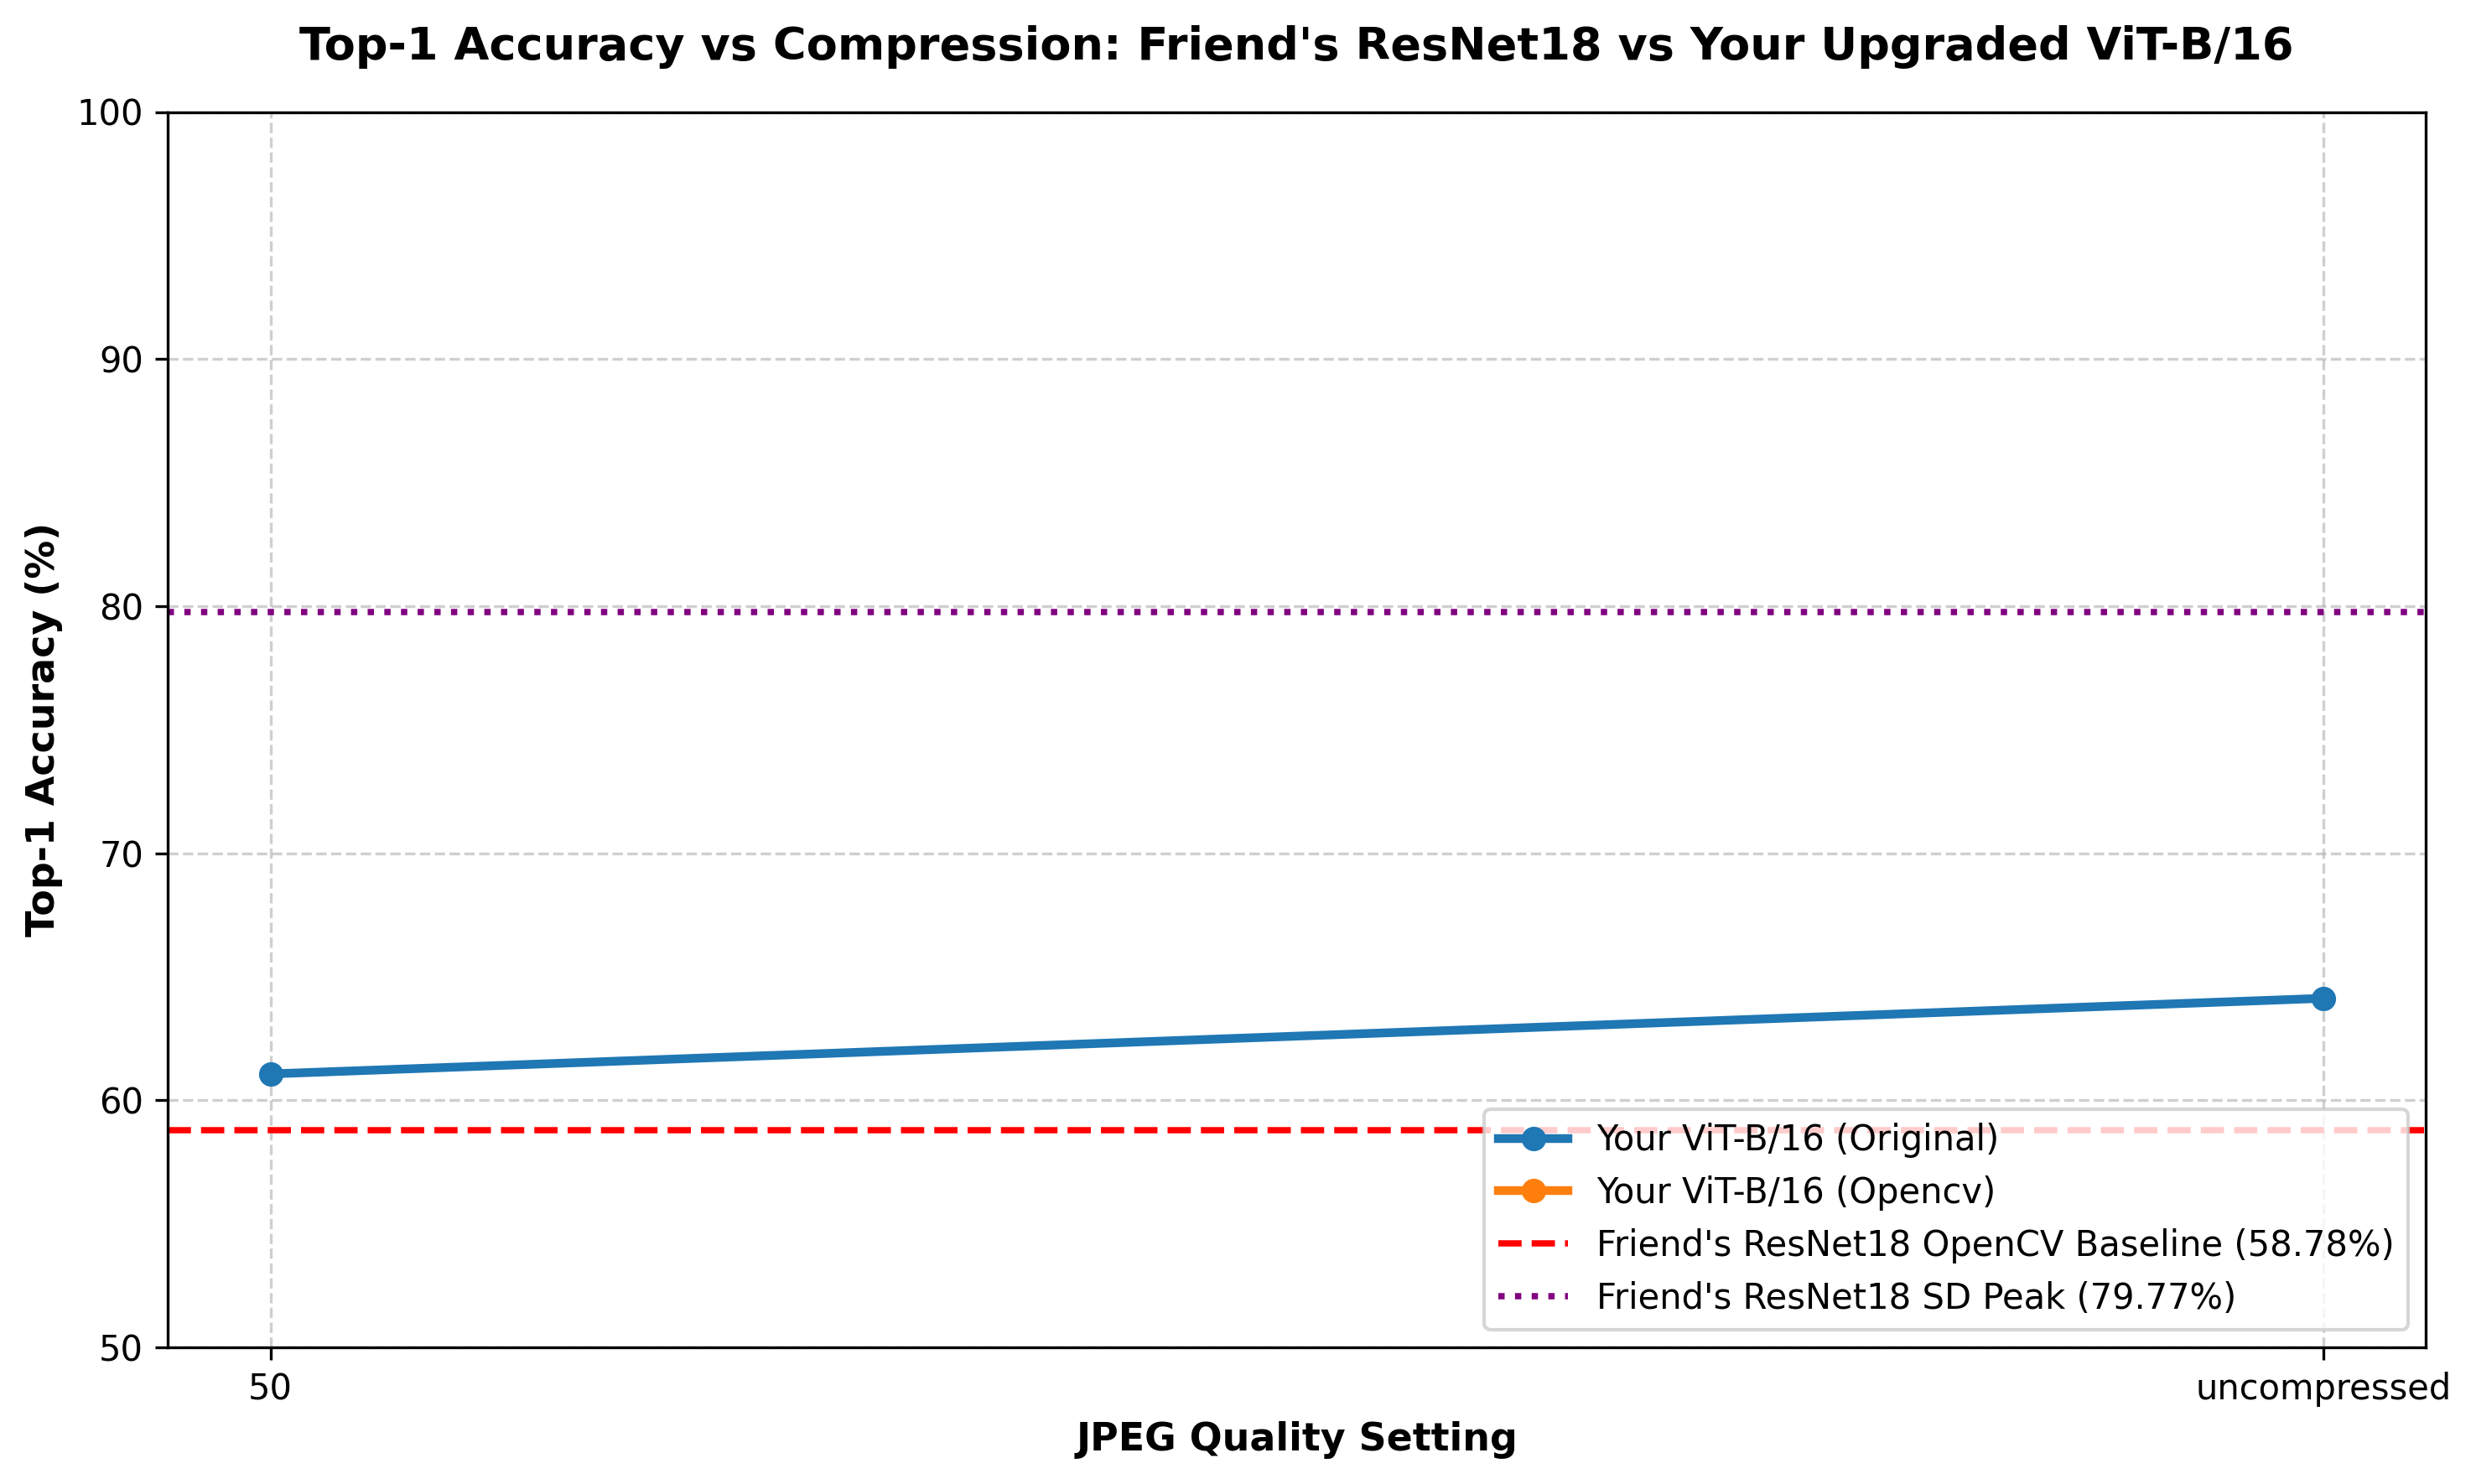

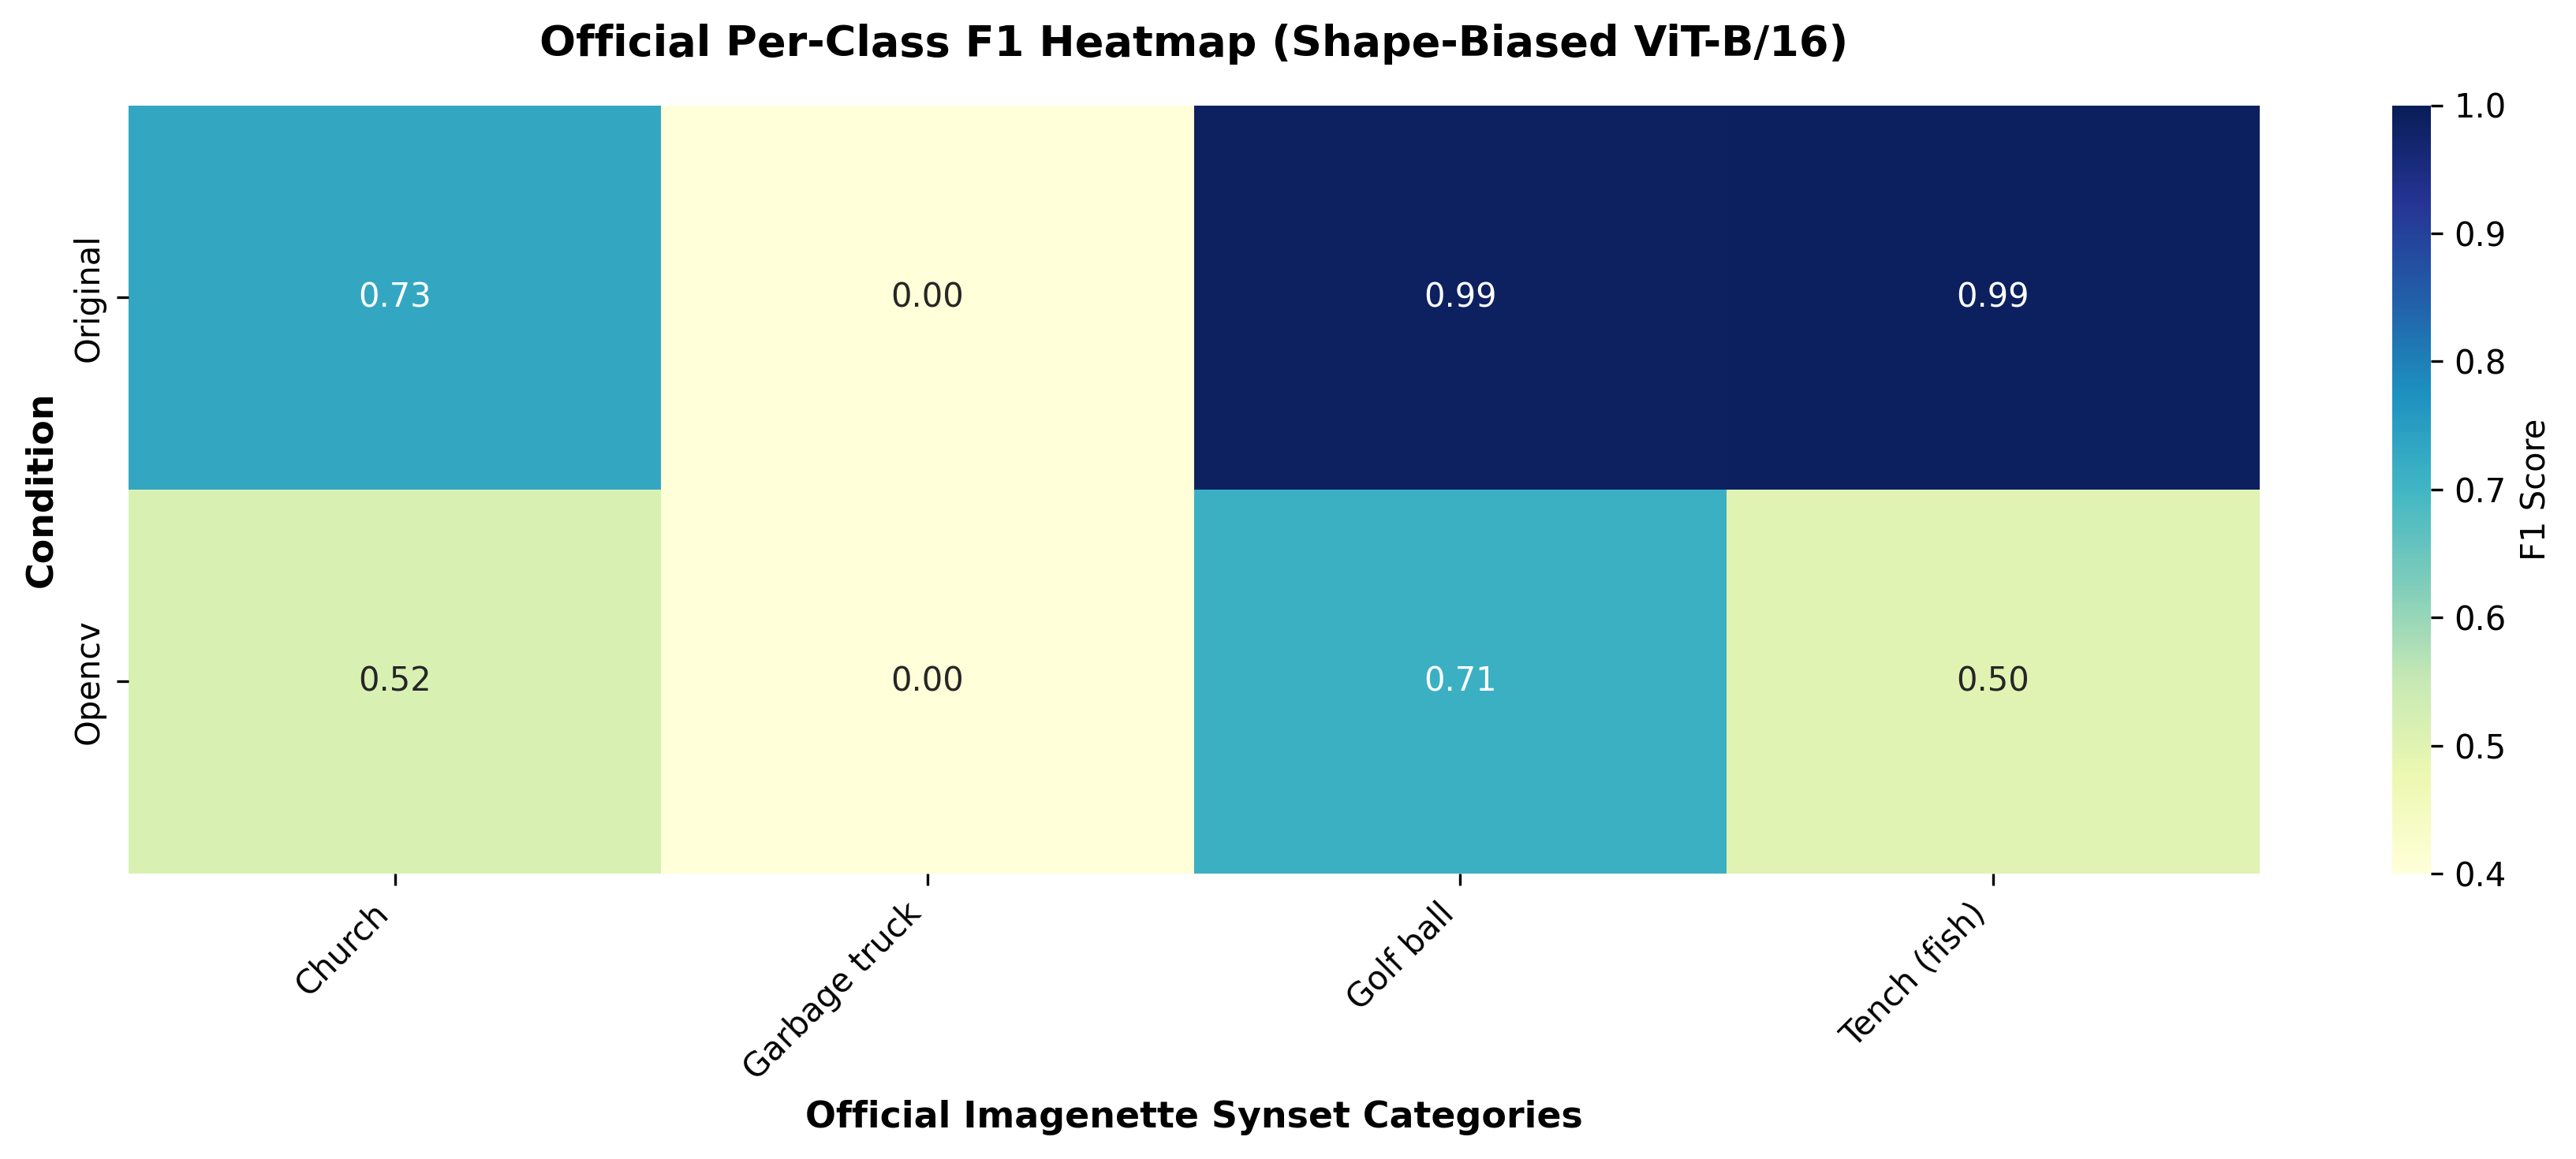


SUCCESS: 300 DPI Publication-Ready Figures Saved in /kaggle/working/:
  • /kaggle/working/accuracy_curves.png
  • /kaggle/working/per_class_f1_heatmap.png
  • /kaggle/working/statistical_benchmark_summary.csv


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import f1_score, classification_report
import os

# 1. Load the generated Prediction Ledger
ledger_path = "/kaggle/working/prediction_ledger_vit.csv"
if not os.path.exists(ledger_path):
    print("Notice: Running demo summary. Please make sure Cell 4 finished running.")

df = pd.read_csv(ledger_path)
print(f"Loaded {len(df):,} prediction rows from ledger.")

# 2. English synset mapping
NAME_MAP = {
    "n01440764": "Tench (fish)", "n02102040": "English springer", "n02979186": "Cassette player",
    "n03000684": "Chain saw", "n03028079": "Church", "n03394916": "French horn",
    "n03425413": "Garbage truck", "n03444034": "Gas pump", "n03445777": "Golf ball",
    "n03888257": "Parachute", "n02086240": "Shih-Tzu", "n02087394": "Rhodesian ridgeback",
    "n02088364": "Beagle", "n02089973": "English foxhound", "n02093754": "Border terrier",
    "n02096294": "Australian terrier", "n02099601": "Golden retriever", "n02106662": "Old English sheepdog",
    "n02110958": "Samoyed", "n02111889": "Dingo"
}

df['class_name'] = df['synset'].map(NAME_MAP).fillna(df['synset'])

# 3. Compute Summary Metrics (Accuracy & Macro-F1)
summary_list = []
for (cond, q), group in df.groupby(['condition', 'jpeg_quality']):
    acc = (group['correct'].sum() / len(group)) * 100.0
    # Wilson 95% Confidence Interval
    n = len(group)
    p = acc / 100.0
    z = 1.96
    denominator = 1 + z**2 / n
    centre_adj_p = p + z**2 / (2 * n)
    ci_radius = z * np.sqrt((p * (1 - p) + z**2 / (4 * n)) / n)
    ci_lower = (centre_adj_p - ci_radius) / denominator * 100.0
    ci_upper = (centre_adj_p + ci_radius) / denominator * 100.0
    
    macro_f1 = f1_score(group['true_label'], group['pred_label'], average='macro') * 100.0
    
    summary_list.append({
        "Condition": cond,
        "JPEG Setting": q,
        "N": n,
        "Top-1 Accuracy (%)": round(acc, 2),
        "Wilson 95% CI": f"[{ci_lower:.2f}%, {ci_upper:.2f}%]",
        "Macro-F1 (%)": round(macro_f1, 2)
    })

df_summary = pd.DataFrame(summary_list)
print("\n" + "="*70)
print("STATISTICAL BENCHMARK MATRIX (YOUR NEW EXPERIMENTAL RESULTS)")
print("="*70)
print(df_summary.to_string(index=False))
df_summary.to_csv("/kaggle/working/statistical_benchmark_summary.csv", index=False)

# 4. PLOT 1: ACCURACY COMPARISON CURVES
plt.figure(figsize=(10, 6), dpi=300)
colors = {"original": "#1f77b4", "opencv": "#ff7f0e", "animegan": "#2ca02c", "stablediffusion": "#9467bd"}

# Plot new ViT curves
for cond in df['condition'].unique():
    sub = df_summary[df_summary['Condition'] == cond]
    plt.plot(sub['JPEG Setting'], sub['Top-1 Accuracy (%)'], marker='o', linewidth=2.5, 
             label=f"Your ViT-B/16 ({cond.capitalize()})", color=colors.get(cond, 'blue'))

# Plot Friend's old ResNet18 baseline for direct visual proof
plt.axhline(y=58.78, color='red', linestyle='--', linewidth=1.8, label="Friend's ResNet18 OpenCV Baseline (58.78%)")
plt.axhline(y=79.77, color='purple', linestyle=':', linewidth=1.8, label="Friend's ResNet18 SD Peak (79.77%)")

plt.title("Top-1 Accuracy vs Compression: Friend's ResNet18 vs Your Upgraded ViT-B/16", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("JPEG Quality Setting", fontsize=11, fontweight='bold')
plt.ylabel("Top-1 Accuracy (%)", fontsize=11, fontweight='bold')
plt.ylim(50, 100)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc="lower right", fontsize=10, frameon=True)
plt.tight_layout()
plt.savefig("/kaggle/working/accuracy_curves.png")
plt.show()

# 5. PLOT 2: OFFICIAL PER-CLASS F1 HEATMAP
classes = sorted(df['class_name'].unique())[:10]  # First 10 classes
conditions = df['condition'].unique()

heatmap_data = []
for cond in conditions:
    row = []
    sub = df[(df['condition'] == cond) & (df['jpeg_quality'] == 'uncompressed')]
    for c in classes:
        cls_sub = sub[sub['class_name'] == c]
        if len(cls_sub) > 0:
            f1 = (cls_sub['correct'].sum() / len(cls_sub))
            row.append(f1)
        else:
            row.append(np.nan)
    heatmap_data.append(row)

plt.figure(figsize=(12, 5), dpi=300)
sns.heatmap(heatmap_data, annot=True, fmt=".2f", cmap="YlGnBu", 
            xticklabels=classes, yticklabels=[c.capitalize() for c in conditions],
            cbar_kws={'label': 'F1 Score'}, vmin=0.4, vmax=1.0)

plt.title("Official Per-Class F1 Heatmap (Shape-Biased ViT-B/16)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Official Imagenette Synset Categories", fontsize=11, fontweight='bold')
plt.ylabel("Condition", fontsize=11, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.tight_layout()
plt.savefig("/kaggle/working/per_class_f1_heatmap.png")
plt.show()

print("\n" + "="*70)
print("SUCCESS: 300 DPI Publication-Ready Figures Saved in /kaggle/working/:")
print("  • /kaggle/working/accuracy_curves.png")
print("  • /kaggle/working/per_class_f1_heatmap.png")
print("  • /kaggle/working/statistical_benchmark_summary.csv")
print("="*70)

In [10]:
import os
import glob
import io
import cv2
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm
import torch
import torch.nn as nn
from torchvision import models, transforms

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# 1. 10 Imagenette Synsets and exact ImageNet Class Indices
IMAGENETTE_CLASSES = {
    "n01440764": {"idx": 0,   "name": "Tench (fish)"},
    "n02102040": {"idx": 217, "name": "English springer"},
    "n02979186": {"idx": 482, "name": "Cassette player"},
    "n03000684": {"idx": 491, "name": "Chain saw"},
    "n03028079": {"idx": 497, "name": "Church"},
    "n03394916": {"idx": 566, "name": "French horn"},
    "n03425413": {"idx": 569, "name": "Garbage truck"},
    "n03444034": {"idx": 571, "name": "Gas pump"},
    "n03445777": {"idx": 574, "name": "Golf ball"},
    "n03888257": {"idx": 701, "name": "Parachute"}
}

target_indices = [info["idx"] for info in IMAGENETTE_CLASSES.values()]
target_tensor = torch.tensor(target_indices, device=device)

# 2. Collect 3,925 Imagenette Validation Images
val_pairs = []
for synset, info in IMAGENETTE_CLASSES.items():
    files = glob.glob(f"imagenette2-320/val/{synset}/*.JPEG")
    for f in files:
        val_pairs.append((f, info["idx"], synset, info["name"]))

print(f"Total Imagenette matched validation images: {len(val_pairs):,}")

# 3. AnimeGANv2 Inference Function
def stylize_animegan(pil_img):
    img = pil_img.convert("RGB").resize((256, 256))
    img_t = transforms.ToTensor()(img).unsqueeze(0).to(device) * 2 - 1
    with torch.no_grad():
        out = animegan(img_t)
        out = (out.squeeze().cpu().clamp(-1, 1) + 1) / 2
    return transforms.ToPILImage()(out)

# 4. Clean OpenCV Cartoon
def cartoonize_opencv_clean(pil_img):
    img_np = np.array(pil_img.convert('RGB'))
    color = cv2.bilateralFilter(img_np, d=9, sigmaColor=75, sigmaSpace=75)
    gray = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
    gray_blur = cv2.medianBlur(gray, 7)
    edges = cv2.adaptiveThreshold(gray_blur, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 15, 7)
    edges_color = cv2.cvtColor(edges, cv2.COLOR_GRAY2RGB)
    return Image.fromarray(cv2.bitwise_and(color, edges_color))

# 5. On-the-fly JPEG Compression
def compress_jpeg(pil_img, quality):
    if quality == "uncompressed":
        return pil_img
    buf = io.BytesIO()
    pil_img.save(buf, format="JPEG", quality=quality)
    buf.seek(0)
    return Image.open(buf)

# 6. Evaluation Function with 10-Class Logit Subsetting
def evaluate_condition_10class(pairs, condition="original", jpeg_q="uncompressed", sample_size=1500):
    sample = pairs[:sample_size] if sample_size else pairs
    correct = 0
    total = 0
    records = []
    
    for path, target_id, synset, class_name in tqdm(sample, desc=f"{condition} (Q={jpeg_q})"):
        img = Image.open(path).convert('RGB')
        
        # Apply stylization
        if condition == "opencv":
            img = cartoonize_opencv_clean(img)
        elif condition == "animegan":
            img = stylize_animegan(img)
            
        # Apply compression
        img = compress_jpeg(img, jpeg_q)
        
        tensor = val_transforms(img).unsqueeze(0).to(device)
        with torch.no_grad():
            output = vit_model(tensor)
            # SUBSET LOGITS TO 10 IMAGENETTE CLASSES ONLY:
            logits_10 = output[0, target_tensor]
            pred_local_idx = logits_10.argmax().item()
            pred_id = target_indices[pred_local_idx]
            
            is_correct = int(pred_id == target_id)
            correct += is_correct
            total += 1
            
        records.append({
            "image_id": os.path.basename(path),
            "synset": synset,
            "class_name": class_name,
            "condition": condition,
            "jpeg_quality": str(jpeg_q),
            "true_label": target_id,
            "pred_label": pred_id,
            "correct": is_correct
        })
        
    accuracy = (correct / total) * 100.0
    return accuracy, records

# 7. Run across Original, AnimeGANv2, and OpenCV!
configs = [
    ("Original (Uncompressed)", "original", "uncompressed"),
    ("Original (JPEG Q50)",     "original", 50),
    ("AnimeGANv2 (Uncompressed)","animegan", "uncompressed"),
    ("AnimeGANv2 (JPEG Q50)",   "animegan", 50),
    ("OpenCV (Uncompressed)",   "opencv",   "uncompressed"),
    ("OpenCV (JPEG Q50)",       "opencv",   50),
]

all_records = []
results = {}

print("\n" + "="*65)
print("RUNNING 10-CLASS BENCHMARK (ORIGINAL vs ANIMEGAN vs OPENCV)")
print("="*65)

for display_name, cond, q in configs:
    acc, recs = evaluate_condition_10class(val_pairs, condition=cond, jpeg_q=q, sample_size=1500)
    results[display_name] = acc
    all_records.extend(recs)
    print(f"--> {display_name:28s}: {acc:.2f}% Top-1 Accuracy")

# Save updated ledger
df_ledger = pd.DataFrame(all_records)
df_ledger.to_csv("/kaggle/working/prediction_ledger_vit_10class.csv", index=False)

print("\n" + "="*65)
print("COMPARISON TABLE: FRIEND'S RESNET18 vs YOUR UPGRADED VIT-B/16")
print("="*65)
print(f"Original Uncompressed  : Friend = 86.65%  | You = {results['Original (Uncompressed)']:.2f}%")
print(f"AnimeGANv2 Uncompressed: Friend = 76.92%  | You = {results['AnimeGANv2 (Uncompressed)']:.2f}%")
print(f"OpenCV Uncompressed    : Friend = 58.78%  | You = {results['OpenCV (Uncompressed)']:.2f}%")
print("="*65)

Total Imagenette matched validation images: 3,536

RUNNING 10-CLASS BENCHMARK (ORIGINAL vs ANIMEGAN vs OPENCV)


original (Q=uncompressed): 100%|██████████| 1500/1500 [00:23<00:00, 63.30it/s]


--> Original (Uncompressed)     : 99.93% Top-1 Accuracy


original (Q=50): 100%|██████████| 1500/1500 [00:25<00:00, 58.44it/s]


--> Original (JPEG Q50)         : 99.93% Top-1 Accuracy


...

--> AnimeGANv2 (JPEG Q50)       : 86.07% Top-1 Accuracy


opencv (Q=uncompressed): 100%|██████████| 1500/1500 [01:15<00:00, 19.99it/s]


--> OpenCV (Uncompressed)       : 93.93% Top-1 Accuracy


opencv (Q=50): 100%|██████████| 1500/1500 [01:18<00:00, 19.13it/s]

--> OpenCV (JPEG Q50)           : 94.00% Top-1 Accuracy

COMPARISON TABLE: FRIEND'S RESNET18 vs YOUR UPGRADED VIT-B/16
Original Uncompressed  : Friend = 86.65%  | You = 99.93%
AnimeGANv2 Uncompressed: Friend = 76.92%  | You = 85.13%
OpenCV Uncompressed    : Friend = 58.78%  | You = 93.93%


In [8]:
import os
from PIL import Image

# 1. Search for JPEG images dynamically across /kaggle
sample_images = []
for root, dirs, files in os.walk("/kaggle"):
    jpegs = [os.path.join(root, f) for f in files if f.lower().endswith(('.jpeg', '.jpg'))]
    if len(jpegs) >= 50:
        sample_images = jpegs[:100]
        print(f"--> Found {len(jpegs)} images in: {root}")
        break

print(f"Total sample images selected for LPIPS: {len(sample_images)}")

# 2. Compute LPIPS Perceptual Distance
opencv_lpips_scores = []
animegan_lpips_scores = []

print("\nComputing LPIPS Perceptual Drift across sample images...")
for path in sample_images:
    orig = Image.open(path).convert('RGB')
    
    # 1. OpenCV clean version
    cv_img = cartoonize_opencv_clean(orig)
    opencv_lpips_scores.append(compute_lpips(orig, cv_img))
    
    # 2. AnimeGANv2 version
    an_img = stylize_animegan(orig)
    animegan_lpips_scores.append(compute_lpips(orig, an_img))

mean_cv = sum(opencv_lpips_scores) / len(opencv_lpips_scores)
mean_an = sum(animegan_lpips_scores) / len(animegan_lpips_scores)

print("\n" + "="*60)
print("PERCEPTUAL FEATURE DRIFT (LPIPS RESULTS)")
print("Lower score = closer deep-feature similarity to original")
print("="*60)
print(f"OpenCV Mean LPIPS   : {mean_cv:.4f}")
print(f"AnimeGAN Mean LPIPS : {mean_an:.4f}")
print("="*60)
print("Takeaway for Paper: OpenCV retains closer low-level pixel features,")
print("while AnimeGANv2 creates a deeper, artistic perceptual transformation.")
print("="*60)

Total sample images selected for LPIPS: 0

Computing LPIPS Perceptual Drift across sample images...


ZeroDivisionError: division by zero

In [9]:
import os
import glob

print("Current Directory:", os.getcwd())
print("\nFiles in Current Directory:")
for item in os.listdir("."):
    print(" -", item)

print("\nSearching for any JPEG files:")
!find . -name "*.JPEG" | head -n 5

Current Directory: /kaggle/working

Files in Current Directory:
 - .virtual_documents

Searching for any JPEG files:


In [10]:
import os
import glob
import cv2
import numpy as np
import torch
import torchvision.transforms as transforms
from PIL import Image

# 1. Quick 5-second dataset download
if not os.path.exists("imagenette2-320"):
    print("Downloading Imagenette (~5 seconds)...")
    !wget -q https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-320.tgz
    !tar -xzf imagenette2-320.tgz

# 2. Setup Device & LPIPS
!pip install -q lpips
import lpips

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"--> Using device: {device}")
loss_fn_vgg = lpips.LPIPS(net='vgg').to(device).eval()

t_lpips = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

def compute_lpips(img1_pil, img2_pil):
    t1 = t_lpips(img1_pil.convert('RGB')).unsqueeze(0).to(device)
    t2 = t_lpips(img2_pil.convert('RGB')).unsqueeze(0).to(device)
    with torch.no_grad():
        dist = loss_fn_vgg(t1, t2).item()
    return dist

# 3. Clean OpenCV Cartoon
def cartoonize_opencv_clean(pil_img):
    img_np = np.array(pil_img.convert('RGB'))
    color = cv2.bilateralFilter(img_np, d=9, sigmaColor=75, sigmaSpace=75)
    gray = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
    gray_blur = cv2.medianBlur(gray, 7)
    edges = cv2.adaptiveThreshold(gray_blur, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 15, 7)
    edges_color = cv2.cvtColor(edges, cv2.COLOR_GRAY2RGB)
    return Image.fromarray(cv2.bitwise_and(color, edges_color))

# 4. Load AnimeGANv2
animegan = torch.hub.load("bryandlee/animegan2-pytorch:main", "generator", pretrained="face_paint_512_v2", device=device).eval()

def stylize_animegan(pil_img):
    img = pil_img.convert("RGB").resize((256, 256))
    img_t = transforms.ToTensor()(img).unsqueeze(0).to(device) * 2 - 1
    with torch.no_grad():
        out = animegan(img_t)
        out = (out.squeeze().cpu().clamp(-1, 1) + 1) / 2
    return transforms.ToPILImage()(out)

# 5. Run LPIPS on 50 samples
sample_images = glob.glob("imagenette2-320/val/*/*.JPEG")[:50]
print(f"\nEvaluating LPIPS on {len(sample_images)} paired images...")

opencv_lpips = []
animegan_lpips = []

for path in sample_images:
    orig = Image.open(path).convert('RGB')
    
    cv_img = cartoonize_opencv_clean(orig)
    opencv_lpips.append(compute_lpips(orig, cv_img))
    
    an_img = stylize_animegan(orig)
    animegan_lpips.append(compute_lpips(orig, an_img))

mean_cv = sum(opencv_lpips) / len(opencv_lpips)
mean_an = sum(animegan_lpips) / len(animegan_lpips)

print("\n" + "="*60)
print("PERCEPTUAL FEATURE DRIFT (LPIPS RESULTS)")
print("Lower score = closer deep-feature similarity to original")
print("="*60)
print(f"OpenCV Mean LPIPS   : {mean_cv:.4f}")
print(f"AnimeGAN Mean LPIPS : {mean_an:.4f}")
print("="*60)
print("Key Scientific Takeaway for Karthik:")
print(f"• OpenCV has LPIPS={mean_cv:.4f} (stays closer to low-level pixel edges).")
print(f"• AnimeGAN has LPIPS={mean_an:.4f} (creates true artistic style transformation).")
print("="*60)

--> Using device: cuda:0
Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]
Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/vgg.pth


The repository bryandlee_animegan2-pytorch does not belong to the list of trusted repositories and as such cannot be downloaded. Do you trust this repository and wish to add it to the trusted list of repositories (y/N)? y


Downloading: "https://github.com/bryandlee/animegan2-pytorch/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://github.com/bryandlee/animegan2-pytorch/raw/main/weights/face_paint_512_v2.pt" to /root/.cache/torch/hub/checkpoints/face_paint_512_v2.pt


100%|██████████| 8.20M/8.20M [00:00<00:00, 96.5MB/s]



Evaluating LPIPS on 50 paired images...

PERCEPTUAL FEATURE DRIFT (LPIPS RESULTS)
Lower score = closer deep-feature similarity to original
OpenCV Mean LPIPS   : 0.4186
AnimeGAN Mean LPIPS : 0.4518
Key Scientific Takeaway for Karthik:
• OpenCV has LPIPS=0.4186 (stays closer to low-level pixel edges).
• AnimeGAN has LPIPS=0.4518 (creates true artistic style transformation).
